# B-IRT on the complete data — diagnostic, the 20 DA items

`birt` only, fit on `data_wdfab/WDFAB_ExperimentalData_Full.dta`.
**Generated by `notebooks/make_design_notebooks.py` — edit the generator,
not this file.** All fitting logic lives in `mice_imp/`; this notebook sets
the frame, calls in, and plots.

## What the file is

The same 1363 respondents, 128 columns, row order and `grp_final` as the
design files, with **no design masking**: 8.33% of the 27 CM cells are
missing, all of it baseline nonresponse, and every item is observed in every
form. Verified on arrival (2026-10-08) against all nine design files (main,
`_small`, `_alt`): zero disagreements on cells both observe, and every
administered (design, form, item) cell has exactly this file's respondents.
The masked designs are cut from it.

It carries `Bike_2_r_cor` for all 1191 bike respondents, matching the
recode table `1->4 2->3 3->2 4->1 5->5` exactly, so `load_cm` reads it
rather than deriving it (CLAUDE.md fact 16).

## This item set

The 20 adapted `DA*` items only, bicycling block dropped. On the full run the
design B-IRT fits agree with this frame on the DA discriminations (median
ratio 0.96 to 1.02) but put the bike slopes about 35% lower, most likely
because the seven locally dependent bike items are only ever answered
together here. Without the bike block that effect is gone, so this run shows
how the designs compare when it is out of the picture. It is also the
reference for the `nobike` design runs, which are the cells where B-MI
converges.

## Why it is a diagnostic, not an arm

This is **not** the CD reference — that calibration belongs to the coauthor
(CLAUDE.md "Scope"), and nothing here is handed over as one. It is also not a
seventh cell of the grid. It answers questions the masked runs cannot:

1. **Is the sampler's trouble caused by masking or by the data?** On a frame
   with nothing masked, divergences and R-hat failures can only come from the
   data. Preflight check 2b FAILs here too: `DA068` has 10 responses in one
   category, `DA053` 13, `DA061` 15 (open issue E). Issue E's earlier
   500-warmup probe found CD diverging as badly as Binterlaced; this is the
   full-length version of that probe.
2. **How far does each design's B-IRT land from the unmasked B-IRT?** The
   same engine, sampler and priors on the same people, with and without the
   mask. That isolates what the design costs our arm.

Read (2) with handover fact 2 in mind: every run is standardised on its own
(`standardize_marginal`, theta ~ N(0,1) within the run). All runs here
standardise over the same 1363 respondents, so the metrics are close, but
they are **not linked** — a uniform shift or stretch between a design and
this fit is identification, not error.

Outputs go to `results_cd/nobike/`, never `results/`, and
the exported CSVs carry `design = "cd"` and `variant = "complete_data"`.

## Setup

In [1]:
import os
import sys
from pathlib import Path

REPO = Path("/home/luis/CGE/mice_imp")
sys.path.insert(0, str(REPO))

os.environ.setdefault("JAX_PLATFORMS", "cpu")
os.environ.setdefault("JAX_ENABLE_X64", "1")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mice_imp.wdfab_io import DA_KEYS as FIT_KEYS, FORM_KEY, load_cm, describe
from mice_imp.cm_bayes_arms import fit_arm
from mice_imp.export_estimates import _load_arm

ITEMSET = "nobike"
DATA_PATH = REPO / "data_wdfab" / "WDFAB_ExperimentalData_Full.dta"
OUTPUT_DIR = REPO / "results_cd" / ITEMSET

CARDINALITY = 5
SEED = 42

# A finished birt.npz in OUTPUT_DIR is loaded rather than refit. The full
# fit takes hours; set REFIT = True to run it again anyway.
REFIT = False

# SMOKE = True is a wiring check, not an inferential run. It writes to
# OUTPUT_DIR like the real fit does, so set REFIT = True for the real one
# afterwards.
SMOKE = False

if SMOKE:
    NUM_CHAINS, NUM_WARMUP, NUM_SAMPLES = 2, 200, 200
else:
    NUM_CHAINS, NUM_WARMUP, NUM_SAMPLES = 4, 3000, 2000

# The grid's sampler, so the comparison with the design runs below differs
# by the mask and nothing else.
STEP_SIZE, TARGET_ACCEPT = 0.0005, 0.98

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"items={ITEMSET} ({len(FIT_KEYS)})  smoke={SMOKE}  chains={NUM_CHAINS} "
      f"warmup={NUM_WARMUP} samples={NUM_SAMPLES}")
print(f"out: {OUTPUT_DIR}")

items=nobike (20)  smoke=False  chains=4 warmup=3000 samples=2000
out: /home/luis/CGE/mice_imp/results_cd/nobike


## Load

`load_cm` reads with `convert_categoricals=False`, shifts 1..5 onto 0..4 and
raises on anything out of range (CLAUDE.md facts 1 and 15).

The check below confirms this is the unmasked frame: under any design some
item has **no** responses in some form. Here none may.

In [2]:
df = load_cm(DATA_PATH, cardinality=CARDINALITY)
describe(df, FIT_KEYS)

fitting_frame = df[FIT_KEYS]
observed_per_form = fitting_frame.notna().groupby(df[FORM_KEY]).sum()
unadministered = (observed_per_form == 0).sum().sum()
assert unadministered == 0, (
    f"{unadministered} (form, item) cells have no responses -- this is a "
    "masked design file, not the complete-data frame")
print(f"\nfitting frame: {fitting_frame.shape[0]} x {fitting_frame.shape[1]}, "
      f"{fitting_frame.isna().to_numpy().mean():.2%} missing, every item in every form")

N = 1363   items = 20   missing = 6.8%   complete rows = 926

administered items by grp_final (x = administered, . = masked by design):
  form  1.0  n=  455  xxxxxxxxxxxxxxxxxxxx  (20 items)
  form  2.0  n=  454  xxxxxxxxxxxxxxxxxxxx  (20 items)
  form  3.0  n=  454  xxxxxxxxxxxxxxxxxxxx  (20 items)

  administered in every form (20): ['DA051', 'DA053', 'DA054', 'DA055', 'DA058', 'DA060', 'DA061', 'DA062_r', 'DA063_r', 'DA064', 'DA066', 'DA067', 'DA052', 'DA068', 'DA069_r', 'DA070', 'DA071', 'DA072', 'DA073', 'DA074']

fitting frame: 1363 x 20, 6.82% missing, every item in every form


## Category sparsity

The suspected cause of divergence (open issue E). Items with a category below
20 responses are what preflight 2b fails on; they are marked in every plot
below, so a misfit that sits on them can be read as a sparsity effect.

In [3]:
counts = pd.DataFrame(
    {k: fitting_frame[k].value_counts().reindex(range(CARDINALITY), fill_value=0)
     for k in FIT_KEYS}).T
counts.columns = [f"cat{c}" for c in range(CARDINALITY)]
counts["min"] = counts.min(axis=1)
SPARSE = counts.index[counts["min"] < 20].tolist()
print(f"items with a category < 20: {SPARSE}")
counts.sort_values("min").head(8)

items with a category < 20: ['DA053', 'DA061', 'DA068']


,cat0,cat1,cat2,cat3,cat4,min
DA068,799,364,50,10,49,10
DA053,871,225,24,13,143,13
DA061,915,167,40,15,119,15
DA066,913,162,37,24,136,24
DA069_r,684,346,119,43,33,33
DA067,655,317,103,49,137,49
DA060,715,276,95,49,142,49
DA074,750,286,105,90,54,54


## B-IRT

No imputation model, ADVI warm-start then NUTS — the same `fit_arm` call the
grid makes for `birt`. Check that `Initializing from ADVI solution` appears
in the output (CLAUDE.md fact 17), and note the **mean non-divergent ratio**:
that is the number question 1 is about, and it is only printed, not saved.

In [4]:
npz = OUTPUT_DIR / "birt.npz"
if npz.exists() and not REFIT:
    print(f"loading existing fit: {npz}")
else:
    fit_arm(
        "birt", fitting_frame, FIT_KEYS, CARDINALITY, OUTPUT_DIR,
        imputation_model=None, run_advi=True,
        num_chains=NUM_CHAINS, num_warmup=NUM_WARMUP, num_samples=NUM_SAMPLES,
        step_size=STEP_SIZE, target_accept_prob=TARGET_ACCEPT, seed=SEED,
    )

cd = _load_arm(npz)
assert cd["item_keys"] == list(FIT_KEYS), "item order differs from ITEM_KEYS"
flag = "  <-- ABOVE 1.05, do not read the comparisons below" if cd["max_rhat"] > 1.05 else ""
print(f"max R-hat {cd['max_rhat']:.4f}{flag}")


=== arm: birt ===


compat: patched bayesianquilts.util.training_loop for the batchless marginal-ADVI call (see mice_imp/compat.py).
    ADVI warm-start (100 iterations)
Marginal ADVI (Rao-Blackwellized abilities)
  Item vars: ['difficulties0', 'discriminations', 'ddifficulties']
  Surrogate params: 240
  Rank: 0 (mean-field)


--- Starting Training ---
Patience for early stopping: 3 epochs
LR decay factor on plateau: 0.5
Convergence will be checked every: 1 epoch(s)
Checkpoints will be saved to: None
Optimizing keys: ['mu\\identity\\normal\\loc', 'mu\\identity\\normal\\scale', 'difficulties0\\identity\\normal\\loc', 'difficulties0\\identity\\normal\\scale', 'discriminations\\softplus\\normal\\loc', 'discriminations\\softplus\\normal\\scale', 'ddifficulties\\softplus\\normal\\loc', 'ddifficulties\\softplus\\normal\\scale']
-------------------------


  -> New best loss found. Checkpoint saved.                    
  -> New best loss found. Checkpoint saved.                    
  -> New best loss found. Checkpoint saved.                    
  -> New best loss found. Checkpoint saved.                    
  -> New best loss found. Checkpoint saved.                    
  -> New best loss found. Checkpoint saved.                    
  -> New best loss found. Checkpoint saved.                    


  -> New best loss found. Checkpoint saved.                    
  -> New best loss found. Checkpoint saved.                    


  -> New best loss found. Checkpoint saved.                    


... (45 outputs left out)

    Sampling (2000 steps → 2000 kept, step_size=0.011617)...


    Non-divergent ratio: 0.259



  Kept 4/4 chains
  Mean non-divergent: 0.262
  difficulties0: mean=-0.3078, std=0.5677
  discriminations: mean=2.2172, std=1.1190
  ddifficulties: mean=0.8324, std=0.4037
    R-hat difficulties0: mean=1.0007 max=1.0021
    R-hat discriminations: mean=1.0007 max=1.0019
    R-hat ddifficulties: mean=1.0008 max=1.0032
    max R-hat overall: 1.0032


  Standardizing marginal: mu=-0.1236, sigma=1.1107
    theta after standardisation: mean=-0.0133 sd=1.0309 mean PSD=0.2361
    saved /home/luis/CGE/mice_imp/results_cd/nobike/birt.npz
max R-hat 1.0032


## Per-parameter R-hat

Where the non-convergence sits, if there is any. If it concentrates on the
thresholds of the sparse items, that is issue E showing up as a sampler
failure; if it is spread across the scale, it is something else.

In [5]:
from mice_imp.cm_bayes_arms import rhat

# The sampled parameters, as stored: the first threshold and then the
# threshold INCREMENTS (fact 5), so `dthr2..` are gaps, not thresholds.
z = np.load(npz, allow_pickle=True)
per_item = lambda name: rhat(z[name]).reshape(len(FIT_KEYS), -1)

rhats = pd.DataFrame(
    np.column_stack([per_item("discriminations"), per_item("difficulties0"),
                     per_item("ddifficulties")]),
    index=FIT_KEYS,
    columns=["a", "thr1"] + [f"dthr{k}" for k in range(2, CARDINALITY)],
)
rhats["worst"] = rhats.max(axis=1)
rhats["sparse"] = rhats.index.isin(SPARSE)
num = rhats.columns[:-1]
rhats.sort_values("worst", ascending=False).style.format(
    "{:.3f}", subset=num).background_gradient(
    vmin=1.0, vmax=1.1, cmap="Reds", subset=num)

,a,thr1,dthr2,dthr3,dthr4,worst,sparse
DA071,1.002,1.002,1.003,1.000,1.001,1.003,False
DA061,1.001,1.001,1.001,1.000,1.003,1.003,True
DA074,1.001,1.000,1.001,1.001,1.002,1.002,False
DA070,1.000,1.002,1.002,1.001,1.001,1.002,False
DA073,1.001,1.000,1.000,1.001,1.002,1.002,False
DA069_r,1.001,1.000,1.001,1.002,1.000,1.002,False
DA062_r,1.001,1.002,1.001,1.001,1.001,1.002,False
DA053,1.001,1.002,1.001,1.002,1.001,1.002,True
DA066,1.001,1.000,1.000,1.000,1.002,1.002,False
DA058,1.000,1.002,1.001,1.001,1.000,1.002,False


## Against the masked designs

Each main-design `birt/nobike` run against this fit. Same engine, sampler,
priors and respondents; the only difference is the design mask. Remember the
runs are standardised separately — read the scatter around the diagonal, not
a small uniform offset from it.

Runs that have not been fitted are skipped.

In [6]:
def _tufte(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(direction="out", length=3, width=0.5)


designs = {}
for name in ("commonitem", "standard", "binterlaced"):
    p = REPO / "results" / name / ITEMSET / "birt.npz"
    if p.exists():
        designs[name] = _load_arm(p)
        assert designs[name]["item_keys"] == cd["item_keys"]
    else:
        print(f"  skipping {name}: no {p.relative_to(REPO)}")

sparse_mask = np.isin(FIT_KEYS, SPARSE)
rows = []
for name, res in designs.items():
    rows.append({
        "design": name,
        "max_rhat": res["max_rhat"],
        "a_rmse": float(np.sqrt(np.mean((res["a_mean"] - cd["a_mean"]) ** 2))),
        "b_rmse": float(np.sqrt(np.mean((res["b_mean"] - cd["b_mean"]) ** 2))),
        "b_rmse_sparse": float(np.sqrt(np.mean(
            (res["b_mean"][sparse_mask] - cd["b_mean"][sparse_mask]) ** 2))),
        "b_rmse_rest": float(np.sqrt(np.mean(
            (res["b_mean"][~sparse_mask] - cd["b_mean"][~sparse_mask]) ** 2))),
        "theta_r": float(np.corrcoef(res["eap"], cd["eap"])[0, 1]),
        "theta_rmse": float(np.sqrt(np.mean((res["eap"] - cd["eap"]) ** 2))),
    })
pd.DataFrame(rows).set_index("design").round(4)

,max_rhat,a_rmse,b_rmse,b_rmse_sparse,b_rmse_rest,theta_r,theta_rmse
design,,,,,,,
commonitem,1.0084,0.2041,0.1321,0.1186,0.1343,0.9758,0.2271
standard,1.0157,0.3478,0.1912,0.1752,0.1939,0.9685,0.2582
binterlaced,1.0190,0.3052,0.1572,0.1415,0.1598,0.9648,0.2730


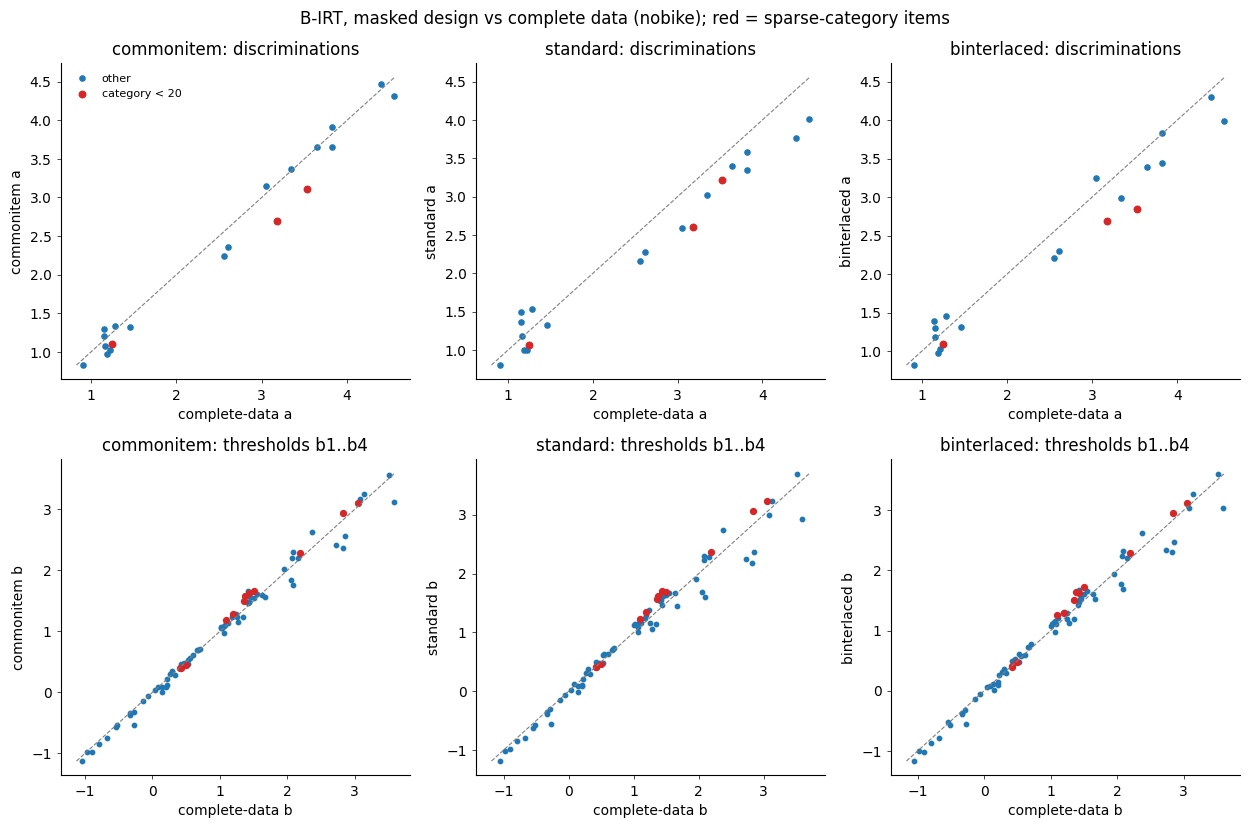

In [7]:
n = max(len(designs), 1)
fig, axes = plt.subplots(2, n, figsize=(4.2 * n, 8.4), squeeze=False)
for j, (name, res) in enumerate(designs.items()):
    ax = axes[0, j]
    ax.scatter(cd["a_mean"][~sparse_mask], res["a_mean"][~sparse_mask], s=14, label="other")
    ax.scatter(cd["a_mean"][sparse_mask], res["a_mean"][sparse_mask], s=22,
               color="C3", label="category < 20")
    lo = min(cd["a_mean"].min(), res["a_mean"].min()); hi = max(cd["a_mean"].max(), res["a_mean"].max())
    ax.plot([lo, hi], [lo, hi], color="gray", lw=0.8, ls="--")
    ax.set_xlabel("complete-data a"); ax.set_ylabel(f"{name} a")
    ax.set_title(f"{name}: discriminations")
    _tufte(ax)

    ax = axes[1, j]
    ax.scatter(cd["b_mean"][~sparse_mask].ravel(), res["b_mean"][~sparse_mask].ravel(), s=10)
    ax.scatter(cd["b_mean"][sparse_mask].ravel(), res["b_mean"][sparse_mask].ravel(), s=18, color="C3")
    lo = min(cd["b_mean"].min(), res["b_mean"].min()); hi = max(cd["b_mean"].max(), res["b_mean"].max())
    ax.plot([lo, hi], [lo, hi], color="gray", lw=0.8, ls="--")
    ax.set_xlabel("complete-data b"); ax.set_ylabel(f"{name} b")
    ax.set_title(f"{name}: thresholds b1..b4")
    _tufte(ax)
if designs:
    axes[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle(f"B-IRT, masked design vs complete data ({ITEMSET}); red = sparse-category items")
fig.tight_layout()

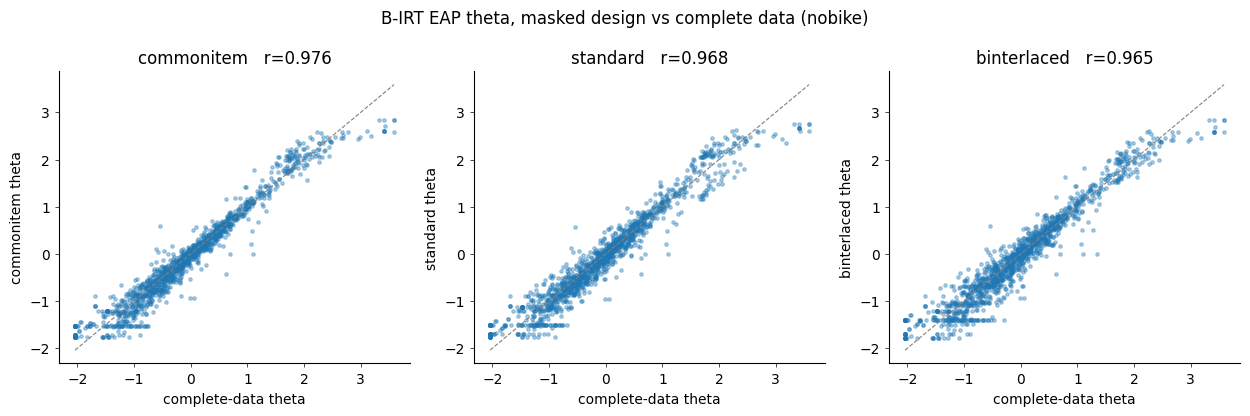

In [8]:
fig, axes = plt.subplots(1, n, figsize=(4.2 * n, 4.2), squeeze=False)
for ax, (name, res) in zip(axes[0], designs.items()):
    ax.scatter(cd["eap"], res["eap"], s=6, alpha=0.35)
    lo = min(cd["eap"].min(), res["eap"].min()); hi = max(cd["eap"].max(), res["eap"].max())
    ax.plot([lo, hi], [lo, hi], color="gray", lw=0.8, ls="--")
    r = float(np.corrcoef(cd["eap"], res["eap"])[0, 1])
    ax.set_xlabel("complete-data theta"); ax.set_ylabel(f"{name} theta")
    ax.set_title(f"{name}   r={r:.3f}")
    _tufte(ax)
fig.suptitle(f"B-IRT EAP theta, masked design vs complete data ({ITEMSET})")
fig.tight_layout()

## Export

The same CSV layout as the grid, so it can be read alongside it. Labelled
`design = "cd"` and `variant = "complete_data"` so it cannot be mistaken for a
design run or pooled with one. It is a diagnostic: if it is sent on, say so,
and say that it is not the CD reference.

In [9]:
from mice_imp.export_estimates import export

export(OUTPUT_DIR, design="cd", itemset=ITEMSET, source=DATA_PATH,
       arms=("birt",), include_d=True, variant="complete_data")

  wrote /home/luis/CGE/mice_imp/results_cd/nobike/item_parameters.csv  (20 rows, arms: birt)
  wrote /home/luis/CGE/mice_imp/results_cd/nobike/theta.csv  (1363 rows)


(Path('/home/luis/CGE/mice_imp/results_cd/nobike/item_parameters.csv'),
 Path('/home/luis/CGE/mice_imp/results_cd/nobike/theta.csv'))